# Urban heat at LA28 facilities (draft solution)

**Proposed final project Task 2. Draft solution for the instructor, not student-facing.**

Every place students need something we haven't covered in class is marked with 🆕 **Not covered in class:**

Summary of what's new for students:

1. Filtering a STAC search by cloud cover (`query=` parameter).
2. Opening a raster with `masked=True` so no-data values become NaN when the file is loaded.
3. Checking that a scene's footprint covers all the facilities.
4. Reading the scale and offset from the STAC metadata to convert the raster to degrees Celsius. The file itself doesn't record them, so rioxarray shows the defaults (scale 1, offset 0).
5. Buffering points (`.buffer()`) to turn facility locations into areas.
6. Calculating a statistic per polygon (a loop over facilities with `rio.clip()`).

Everything else (STAC access with `pystac_client`, `open_rasterio` from an asset href, `squeeze`, `clip_box` + `clip`, no-data values, `points_from_xy`, `to_crs`, `contextily`, pandas plotting) was covered in lessons 4 and 11 to 17 or discussion section 8.

## About

**Event.** NASA JPL's ECOSTRESS team is working with the LA28 Olympics committee on heat mitigation for venues, transportation corridors and pedestrian areas ahead of the 2028 Games. In this task you will make a similar (simpler) analysis with Landsat data: how hot does the ground get around LA28 facilities compared to the Los Angeles urban area as a whole?

**Question.** On a clear late-summer day, which LA28 facilities sit in areas hotter than the urban area's average, and how much of the area around each facility is hotter than that average?

We answer it in **relative** terms: degrees above or below the urban average *on the same date*. Absolute surface temperatures change a lot from one day to the next (see below), but comparisons within one scene are more robust.

**Why Landsat and not ECOSTRESS?** ECOSTRESS is not on the Microsoft Planetary Computer and needs a NASA Earthdata account. Landsat Collection 2 Level-2 includes a surface temperature band and needs no account.

## About the data

1. **Landsat Collection 2 Level-2 surface temperature** (`landsat-c2-l2` collection, `lwir11` asset), from the Microsoft Planetary Computer STAC catalog. Pixels are 30 m, resampled from the thermal sensor's native 100 m.

    **Surface temperature is not air temperature.** Landsat measures the thermal radiation coming off the top millimeter of whatever it sees from above: roofs, pavement, treetops, grass, water. Dark pavement and roofs in full sun often reach 50 to 70 °C, while the air a few feet above them is much cooler. Air temperature (what a weather station reports) is measured in the shade, about 2 m above the ground, and changes much more slowly across a city. Some consequences for this analysis:
    - the satellite sees the top of a roof or a tree canopy, not the shaded sidewalk where people stand;
    - converting radiation to temperature requires assuming how efficiently each surface emits heat (its *emissivity*); this is hard for urban materials such as metal roofs and is a major source of uncertainty, along with the atmospheric correction;
    - dry grass and bare soil get almost as hot as pavement by late summer, while irrigated grass stays cool;
    - surface temperature is a good indicator of where the built environment stores heat (and where shade or vegetation would help), but it is not a direct measure of how hot people feel.

2. **Census 2020 urban areas**, US Census Bureau TIGER/Line 2025 shapefile (`tl_2025_us_uac20.zip`, https://www2.census.gov/geo/tiger/TIGER2025/UAC20/). We use the *Los Angeles--Long Beach--Anaheim, CA* urban area as our reference area: the Census defines urban areas as densely developed territory, so its average temperature represents the city people live in, without the mountains, desert or ocean that a county or city boundary would include.

3. **LA28 facilities** (`la28-facilities.csv`, provided). The 19 **permanent, on-land** LA28 competition facilities in the Los Angeles area, with approximate coordinates. The list comes from the LA28 venue list cross-referenced with Wikipedia's venue statuses. It leaves out:
    - temporary venues (e.g. Venice Beach, Sepulveda Basin, the Long Beach Convention Center lot), since Landsat can only see what is built today;
    - water venues (Port of Los Angeles, Long Beach Marine Stadium, Belmont Pier), since over water Landsat measures the water surface;
    - venues outside the LA area (Trestles, Oklahoma City and the football stadiums in other cities).

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd
import rioxarray as rioxr
import contextily as ctx

from shapely.geometry import shape  # To turn GeoJSON dictionaries into geometries
from pystac_client import Client
import planetary_computer

## Reference area: Los Angeles urban area

The file has every urban area in the US. We keep only Los Angeles.

EPSG:4269
Land area: 4,243 km²
Water area: 46 km²


<Axes: >

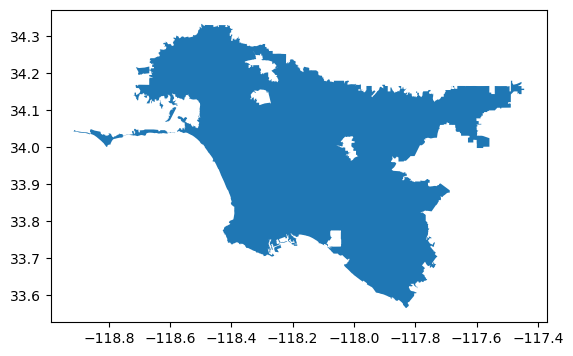

In [2]:
urban = gpd.read_file('data/tl_2025_us_uac20.zip')
urban = urban[urban['NAME20'] == 'Los Angeles--Long Beach--Anaheim, CA']

print(urban.crs)
print(f"Land area: {urban['ALAND20'].iloc[0] / 1000**2:,.0f} km²")
print(f"Water area: {urban['AWATER20'].iloc[0] / 1000**2:,.0f} km²")
urban.plot()

## LA28 facilities

We read the CSV and turn it into a geo-data frame, as in lesson 11.

In [3]:
facilities = pd.read_csv('data/la28-facilities.csv')
facilities = gpd.GeoDataFrame(facilities,
                              geometry=gpd.points_from_xy(facilities['lon'], facilities['lat']),
                              crs='epsg:4326')
facilities[['facility', 'city', 'sports']]

,facility,city,sports
0,BMO Stadium,Los Angeles,Flag Football; Lacrosse
1,Crypto.com Arena,Los Angeles,Artistic Gymnastics; Boxing; Trampoline Gymnas...
2,Dignity Health Sports Park,Carson,Archery; Rugby Sevens; Tennis; Wheelchair Tennis
3,Dodger Stadium,Los Angeles,Baseball
4,Fairplex (Knight Riders Cricket Ground),Pomona,Cricket
5,Galen Center,Los Angeles,Badminton; Para Badminton; Rhythmic Gymnastics...
6,Honda Center,Anaheim,Volleyball
7,Intuit Dome,Inglewood,Basketball
8,LA Clays Shooting Sports Park,Whittier Narrows (unincorporated LA County),Shooting
9,Long Beach Arena,Long Beach,Handball; Sitting Volleyball


Check that every facility is inside the urban area:

In [4]:
facilities.within(urban.to_crs(facilities.crs).geometry.iloc[0]).all()

True

🆕 **Not covered in class:** buffering. A facility is a point, but we want the temperature of the area around it. `.buffer(500)` draws a circle with a 500 m radius around each point.

The buffer distance is in the units of the CRS, so we must reproject to a projected CRS in meters first. Buffering in EPSG:4326 would give a radius of 500 *degrees*. We use UTM zone 11N (EPSG:32611), which is also the Landsat raster's CRS.

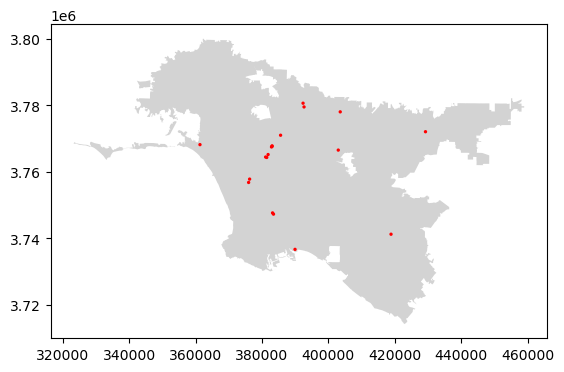

In [5]:
facilities = facilities.to_crs('epsg:32611')
facilities['geometry'] = facilities.buffer(500)

fig, ax = plt.subplots()
urban.to_crs(facilities.crs).plot(ax=ax, color='lightgray')
facilities.plot(ax=ax, color='red')
plt.show()

> **Student decision:** the buffer size. In downtown LA, Crypto.com Arena, Peacock Theater and the LA Convention Center are 200 to 400 m apart, so their 500 m buffers overlap almost completely and give nearly the same numbers. A smaller buffer separates them but holds fewer pixels.

## STAC search: Landsat surface temperature

In [6]:
catalog = Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

# Bounding box of the urban area in lat/lon, as the search expects
urban_bbox = list(urban.to_crs('epsg:4326').total_bounds)

🆕 **Not covered in class:** filtering a search by item properties. Clouds hide the ground from the thermal sensor, so we only want nearly cloud-free scenes. The `query` parameter filters items by any property in their metadata, here `eo:cloud_cover` (a percentage).

> **Instructor note:** `query=` uses the older STAC Query extension. The current standard is CQL2, through the `filter=` parameter (e.g. `filter={'op': '<', 'args': [{'property': 'eo:cloud_cover'}, 10]}`). `query=` still works on the Planetary Computer and is simpler to read, so we keep it here.

In [7]:
search = catalog.search(
    collections=['landsat-c2-l2'],
    bbox=urban_bbox,
    datetime='2026-06-01/2026-09-30',
    query={'eo:cloud_cover': {'lt': 10}},
)
items = search.item_collection()
len(items)

23

🆕 **Not covered in class:** checking a scene's coverage. Landsat scenes are tiles, and the LA urban area sits near the corner of one. We check which footprints contain all the facilities, using `shape()` from lesson 16.

In [8]:
facilities_4326 = facilities.to_crs('epsg:4326')

for item in items:
    footprint = shape(item.geometry)
    print(item.id,
          item.properties['eo:cloud_cover'],
          'covers all facilities:', facilities_4326.within(footprint).all())

LC09_L2SP_041036_20260930_02_T1 0.64 covers all facilities: True
LC08_L2SP_042036_20260929_02_T1 0.15 covers all facilities: False
LC09_L2SP_040036_20260923_02_T1 0.02 covers all facilities: False
LC08_L2SP_041036_20260922_02_T1 0.43 covers all facilities: True
LC08_L2SP_040036_20260915_02_T1 0.87 covers all facilities: False
LC09_L2SP_041036_20260914_02_T1 1.62 covers all facilities: True
LC08_L2SP_042036_20260913_02_T1 4.54 covers all facilities: False
LC09_L2SP_042036_20260905_02_T1 0.05 covers all facilities: False
LC08_L2SP_040037_20260830_02_T1 1.44 covers all facilities: False
LC09_L2SP_040036_20260822_02_T1 0.06 covers all facilities: False
LC08_L2SP_041036_20260821_02_T1 0.21 covers all facilities: True
LC08_L2SP_040036_20260814_02_T1 0.08 covers all facilities: False
LC09_L2SP_040036_20260806_02_T1 1.78 covers all facilities: False
LC08_L2SP_041036_20260805_02_T1 8.48 covers all facilities: True
LC08_L2SP_040036_20260729_02_T1 0.0 covers all facilities: False
LC09_L2SP_041036

We pick the scene from **August 21, 2026** (Landsat 8): it covers all facilities and has the lowest cloud cover.

> **Instructor note:** the scene covers about 99% of the urban area. A sliver at the southeastern tip (around Laguna Niguel) is outside it and comes out as no-data. It doesn't affect the facilities and barely changes the urban average.

> **Student decision:** which date to use. Any clear summer scene works. Students should say why they picked theirs (cloud cover, heat wave, time of year).

In [9]:
item = [i for i in items if i.id == 'LC08_L2SP_041036_20260821_02_T1'][0]

print(item.properties['datetime'])

2026-08-21T18:28:05.822606Z


The time is in UTC: 18:28 UTC is **11:28 am** in Los Angeles. Landsat always passes over in the late morning, before the hottest part of the day. ECOSTRESS's map averaged 1 to 4 pm.

## Surface temperature raster

In [10]:
for key in item.assets.keys():
    print(key, '--', item.assets[key].title)

qa -- Surface Temperature Quality Assessment Band
ang -- Angle Coefficients File
red -- Red Band
blue -- Blue Band
drad -- Downwelled Radiance Band
emis -- Emissivity Band
emsd -- Emissivity Standard Deviation Band
trad -- Thermal Radiance Band
urad -- Upwelled Radiance Band
atran -- Atmospheric Transmittance Band
cdist -- Cloud Distance Band
green -- Green Band
nir08 -- Near Infrared Band 0.8
lwir11 -- Surface Temperature Band
swir16 -- Short-wave Infrared Band 1.6
swir22 -- Short-wave Infrared Band 2.2
coastal -- Coastal/Aerosol Band
mtl.txt -- Product Metadata File (txt)
mtl.xml -- Product Metadata File (xml)
mtl.json -- Product Metadata File (json)
qa_pixel -- Pixel Quality Assessment Band
qa_radsat -- Radiometric Saturation and Terrain Occlusion Quality Assessment Band
qa_aerosol -- Aerosol Quality Assessment Band
tilejson -- TileJSON with default rendering
rendered_preview -- Rendered preview


🆕 **Not covered in class:** `masked=True`. The surface temperature file uses 0 to mark pixels with no data (outside the scene, or where the temperature couldn't be calculated). With `masked=True`, rioxarray turns those pixels into NaN as it loads the file, so they can't sneak into our calculations. Without it, each 0 would become a temperature of -124 °C after the conversion below, and drag every average down.

In [11]:
lst = rioxr.open_rasterio(item.assets['lwir11'].href, masked=True)
lst = lst.squeeze('band', drop=True)

print('CRS:', lst.rio.crs)
print('Resolution:', lst.rio.resolution())
print('No-data value:', lst.rio.nodata)
print('Data type:', lst.dtype)
print('Attributes:', lst.attrs)

CRS: EPSG:32611
Resolution: (30.0, -30.0)
No-data value: nan
Data type: float32
Attributes: {'AREA_OR_POINT': 'Point', 'scale_factor': 1.0, 'add_offset': 0.0}


🆕 **Not covered in class:** scale and offset. The values in the file are integers, not temperatures (`masked=True` turned them into floats so they can hold NaN). To save space, Landsat stores each temperature as an integer, and we have to convert it back with:

$$\text{temperature (K)} = \text{value} \times \text{scale} + \text{offset}$$

The attributes above show `scale_factor: 1.0` and `add_offset: 0.0`. Those are rioxarray's defaults: the file doesn't record how to convert its integers, so a scale of 1 would give values around 47,000 K. The real scale and offset are in the STAC metadata for the asset:

In [12]:
item.assets['lwir11'].extra_fields['raster:bands']

[{'unit': 'kelvin',
  'scale': 0.00341802,
  'nodata': 0,
  'offset': 149,
  'data_type': 'uint16',
  'spatial_resolution': 30}]

## Clip to the urban area

As in lesson 17: match the CRS, clip to the bounding box first, then to the polygon.

In [13]:
urban = urban.to_crs(lst.rio.crs)
assert urban.crs == lst.rio.crs

lst_urban = lst.rio.clip_box(*urban.total_bounds).rio.clip(urban.geometry)

Now convert to °C. Pixels outside the urban area are already NaN, because the raster was opened with `masked=True`.

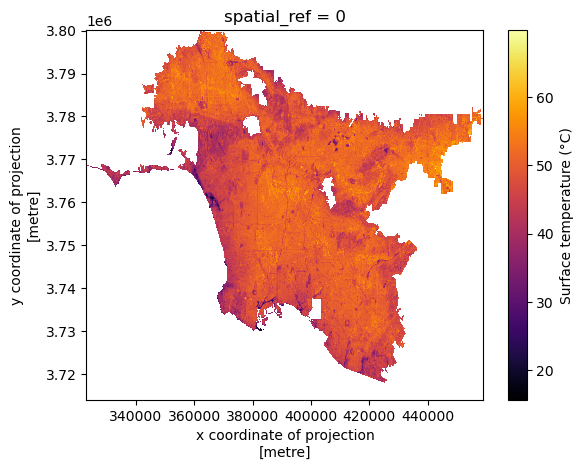

In [14]:
band = item.assets['lwir11'].extra_fields['raster:bands'][0]

lst_urban = lst_urban * band['scale'] + band['offset'] - 273.15   # integers -> K -> °C

lst_urban.plot(cmap='inferno', cbar_kwargs={'label': 'Surface temperature (°C)'})

Quick check that the values make sense:

In [15]:
print(f"Min: {float(lst_urban.min()):.1f} °C")
print(f"Max: {float(lst_urban.max()):.1f} °C")
print(f"Mean: {float(lst_urban.mean()):.1f} °C")

Min: 15.7 °C
Max: 69.9 °C
Mean: 48.7 °C


> **Data check for students:** surface temperatures of 50+ °C are normal for asphalt and rooftops on a summer day. **This is the temperature of the ground, not of the air.** The hottest pixels (60 to 70 °C, less than 0.1% of the area) are airport runways and large warehouse roofs, e.g. around Ontario Airport and Van Nuys Airport. The coolest pixels are water the urban area still includes (reservoirs, harbor channels) and irrigated green spaces.

> **Instructor note: absolute values depend on the date.** Urban-area mean surface temperature on the other clear 2026 scenes I checked: Jun 10: 46.1 °C, Aug 5: 42.4 °C, **Aug 21: 48.7 °C**, Sep 14: 40.1 °C, Sep 22: 38.3 °C. This is why we report results relative to the urban average on the same date.

## Statistics: facilities vs. the urban area

The urban area's average is our reference.

> **Student decision:** the threshold. "Hotter than the urban average" is a simple choice; a fixed temperature (e.g. 50 °C) or a percentile are others. Students should justify theirs.

In [16]:
urban_mean = float(lst_urban.mean())
urban_mean

48.65543746948242

🆕 **Not covered in class:** statistics per polygon. We clip the temperature raster to each facility's buffer, one at a time. Every facility is inside the urban area, so we can clip `lst_urban` directly.

In [17]:
mean_temps = []
pct_hot = []

for geom in facilities.geometry:
    facility_lst = lst_urban.rio.clip([geom])
    n_pixels = int(facility_lst.notnull().sum())
    n_hot = int((facility_lst > urban_mean).sum())

    mean_temps.append(float(facility_lst.mean()))
    pct_hot.append(n_hot / n_pixels * 100)

facilities['mean_temp_c'] = mean_temps
facilities['pct_above_urban_mean'] = pct_hot

# Relative result: difference from the urban average
facilities['diff_from_urban_c'] = facilities['mean_temp_c'] - urban_mean

results = (facilities[['facility', 'city', 'diff_from_urban_c', 'pct_above_urban_mean']]
           .sort_values('diff_from_urban_c', ascending=False)
           .round(1))
results

,facility,city,diff_from_urban_c,pct_above_urban_mean
4,Fairplex (Knight Riders Cricket Ground),Pomona,3.5,96.2
6,Honda Center,Anaheim,2.6,89.6
16,Santa Anita Park,Arcadia,2.6,76.5
3,Dodger Stadium,Los Angeles,1.5,74.5
18,VELO Sports Center,Carson,1.1,63.5
10,Los Angeles Convention Center,Los Angeles,0.9,63.1
1,Crypto.com Arena,Los Angeles,0.4,50.8
12,Peacock Theater,Los Angeles,-0.0,45.6
5,Galen Center,Los Angeles,-0.1,43.2
2,Dignity Health Sports Park,Carson,-0.2,45.7


Each 500 m buffer covers about 870 Landsat pixels, but the thermal sensor's real resolution is 100 m, so each buffer holds only about 80 independent measurements.

We plot each facility's difference from the urban average. Positive means hotter than the urban area.

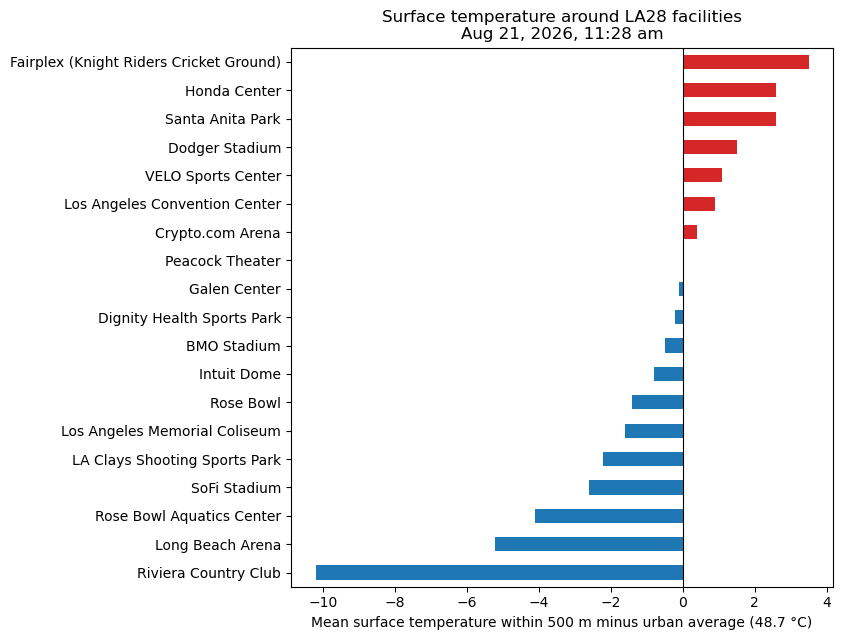

In [18]:
plot_data = results.set_index('facility').sort_values('diff_from_urban_c')
colors = ['tab:red' if d > 0 else 'tab:blue' for d in plot_data['diff_from_urban_c']]

ax = plot_data['diff_from_urban_c'].plot.barh(figsize=(7, 7), color=colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel(f'Mean surface temperature within 500 m minus urban average ({urban_mean:.1f} °C)')
ax.set_ylabel('')
ax.set_title('Surface temperature around LA28 facilities\nAug 21, 2026, 11:28 am')
plt.show()

## Map

Surface temperature over the urban area with the facility buffers and a basemap (contextily, as in discussion section 8).

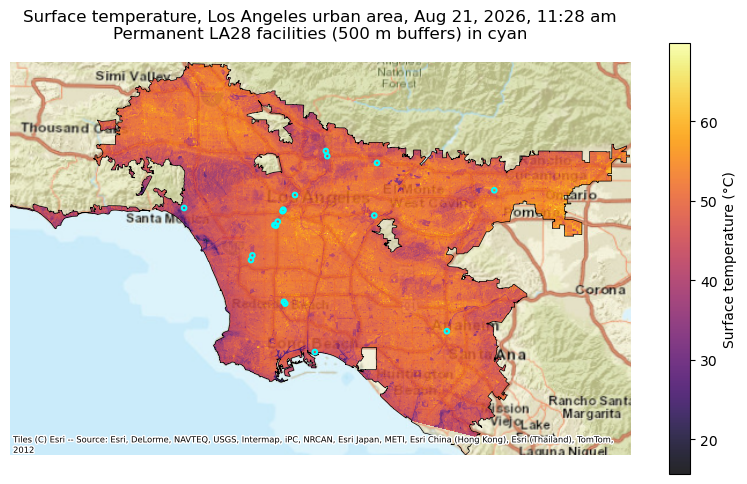

In [19]:
fig, ax = plt.subplots(figsize=(10, 8))

lst_urban.plot(ax=ax, cmap='inferno', alpha=0.85,
               cbar_kwargs={'label': 'Surface temperature (°C)', 'shrink': 0.7})
urban.boundary.plot(ax=ax, color='black', linewidth=0.5)
facilities.boundary.plot(ax=ax, color='cyan', linewidth=1.5)

ctx.add_basemap(ax, crs=urban.crs, source=ctx.providers.Esri.WorldStreetMap, attribution_size=6)

ax.set_title('Surface temperature, Los Angeles urban area, Aug 21, 2026, 11:28 am\n'
             'Permanent LA28 facilities (500 m buffers) in cyan')
ax.set_axis_off()
plt.show()

## Possible reflection questions for students

1. Landsat measured at 11:28 am. Would you expect the ranking of facilities to change in the late afternoon? Why might ECOSTRESS be better for this question?
2. Is surface temperature a good measure of heat risk for spectators? What would you need to know besides it (air temperature, humidity, shade, time spent outdoors)?
3. Landsat estimates the uncertainty of each pixel's surface temperature (the item's `qa` asset); over the LA urban area on Aug 21, 2026, a typical pixel's absolute temperature is uncertain by about ±2 °C. Yet we reported differences from the urban average that are smaller than that. Why can a *relative* difference (a facility vs. the urban average, on the same scene) be more reliable than an *absolute* temperature? Think about which errors affect the whole scene in the same way (e.g. the atmospheric correction) and what happens to random errors when you average many pixels.
4. The thermal band is 100 m resampled to 30 m, and some buffers overlap. Is each facility really measured separately?
5. Water venues were left out. Why would a buffer around Long Beach Marine Stadium be cooler than one around the Coliseum, and why isn't that a fair comparison?
6. The hottest facilities (Fairplex, Honda Center, Santa Anita) are all inland, and the coolest are near the coast or on irrigated grass (Riviera Country Club). Is the difference about the facilities themselves, or about where they are? How could you tell?
7. How would your results change on a different date? Try one more scene.

In [22]:
facilities

,facility,la28_venue_name,city,sports,lat,lon,geometry,mean_temp_c,pct_above_urban_mean,diff_from_urban_c
0,BMO Stadium,Exposition Park Stadium,Los Angeles,Flag Football; Lacrosse,34.01281,-118.28409,"POLYGON ((381931.130 3764319.624, 381928.723 3...",48.180878,46.613088,-0.474560
1,Crypto.com Arena,DTLA Arena,Los Angeles,Artistic Gymnastics; Boxing; Trampoline Gymnas...,34.04300,-118.26714,"POLYGON ((383537.775 3767647.859, 383535.368 3...",49.040562,50.804598,0.385124
2,Dignity Health Sports Park,Carson Stadium; Carson Courts,Carson,Archery; Rugby Sevens; Tennis; Wheelchair Tennis,33.86238,-118.26291,"POLYGON ((383681.643 3747614.553, 383679.235 3...",48.469055,45.704467,-0.186382
3,Dodger Stadium,Dodger Stadium,Los Angeles,Baseball,34.07363,-118.23985,"POLYGON ((386098.073 3771013.526, 386095.665 3...",50.128189,74.455899,1.472752
4,Fairplex (Knight Riders Cricket Ground),Fairgrounds Cricket Stadium,Pomona,Cricket,34.08705,-117.76685,"POLYGON ((429754.592 3772073.322, 429752.185 3...",52.173595,96.211251,3.518158
5,Galen Center,Galen Center,Los Angeles,Badminton; Para Badminton; Rhythmic Gymnastics...,34.02075,-118.27980,"POLYGON ((382338.284 3765195.122, 382335.877 3...",48.591312,43.233945,-0.064125
6,Honda Center,Honda Center,Anaheim,Volleyball,33.80783,-117.87653,"POLYGON ((419371.317 3741194.187, 419368.909 3...",51.287773,89.576174,2.632336
7,Intuit Dome,Intuit Dome,Inglewood,Basketball,33.94426,-118.34217,"POLYGON ((376468.306 3756786.943, 376465.898 3...",47.894077,42.643678,-0.761360
8,LA Clays Shooting Sports Park,Whittier Narrows Clay Shooting Center,Whittier Narrows (unincorporated LA County),Shooting,34.03502,-118.05104,"POLYGON ((403476.534 3766537.049, 403474.126 3...",46.409523,22.540046,-2.245914
9,Long Beach Arena,Long Beach Arena,Long Beach,Handball; Sitting Volleyball,33.76409,-118.18837,"POLYGON ((390451.121 3736633.585, 390448.714 3...",43.446358,5.040092,-5.209080


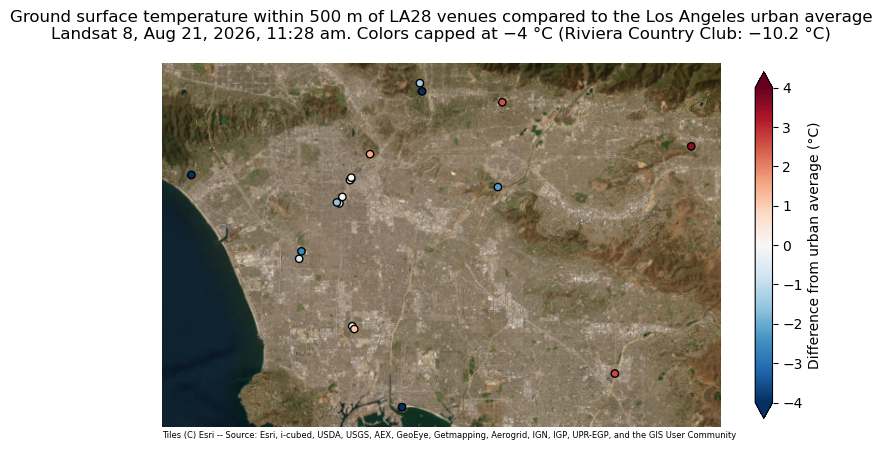

In [37]:
fig, ax = plt.subplots(figsize=(9, 9))
limit = 4   # °C, covers every venue except Riviera

facilities.plot(ax=ax,
                column='diff_from_urban_c',
                cmap='RdBu_r',
                vmin=-limit, vmax=limit,
                edgecolor='black',
                legend=True,
                legend_kwds={'label': 'Difference from urban average (°C)',
                             'shrink': 0.5,
                             'extend': 'both'})   # arrow ends: values beyond the limits
ctx.add_basemap(ax, crs=facilities.crs, source=ctx.providers.Esri.WorldImagery, attribution=False)

ax.set_title('Ground surface temperature within 500 m of LA28 venues compared to the Los Angeles urban average\n'
             'Landsat 8, Aug 21, 2026, 11:28 am. Colors capped at −4 °C '
             '(Riviera Country Club: −10.2 °C)',
             fontsize=12)

# Credit text, placed just below the map
basemap = ctx.providers.Esri.WorldImagery
ax.text(0, -0.01, basemap.attribution,
        transform=ax.transAxes,   # coordinates relative to the map: (0, 0) is its bottom-left corner
        fontsize=6, va='top')
ax.set_axis_off()
plt.show()